<a href="https://colab.research.google.com/github/sandisetiawan552233-png/-Implementasi-Algoritma-Random-Forest-SUHU-KELEMBAPAN-GAS/blob/main/TUBES_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Baca dataset**

In [ ]:

import pandas as pd

df = pd.read_csv('/content/AirQuality_data.csv')

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)


Dataset berhasil dibaca!
Ukuran dataset: (2989, 5)


# **Periksa isi dataset**

In [ ]:

# Melihat nama kolom
print('/content/AirQuality_data.csv')
print(df.columns.tolist())

# Melihat ukuran dataset
print("\nJumlah baris dan kolom:", df.shape)

# Melihat 5 baris pertama
display(df.head())

# Memeriksa data kosong
print("\nJumlah data kosong:")
print(df.isnull().sum())


/content/AirQuality_data.csv
['Unnamed: 0', 'TEMP', 'Hum', 'CO2', 'class']

Jumlah baris dan kolom: (2989, 5)


,Unnamed: 0,TEMP,Hum,CO2,class
0,0,16.0,57,370,0
1,1,16.0,57,360,0
2,2,16.0,57,380,0
3,3,15.0,58,390,0
4,4,15.0,58,380,0



Jumlah data kosong:
Unnamed: 0    0
TEMP          0
Hum           0
CO2           0
class         0
dtype: int64


# **Bersihkan dataset**

In [ ]:
# Menghapus kolom indeks yang tidak diperlukan
df = df.drop(columns=['Unnamed: 0'])

# Memeriksa kembali dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:", df.columns.tolist())

display(df.head())


Ukuran dataset: (2989, 4)

Nama kolom: ['TEMP', 'Hum', 'CO2', 'class']


,TEMP,Hum,CO2,class
0,16.0,57,370,0
1,16.0,57,360,0
2,16.0,57,380,0
3,15.0,58,390,0
4,15.0,58,380,0


# **Periksa distribusi label**

In [ ]:

print("Distribusi label:")
print(df['class'].value_counts())

print("\nProporsi label (%):")
print(
    (df['class'].value_counts(normalize=True) * 100).round(2)
)


Distribusi label:
class
0    2189
1     800
Name: count, dtype: int64

Proporsi label (%):
class
0    73.24
1    26.76
Name: proportion, dtype: float64


# **Tentukan fitur input dan target**

In [ ]:

X = df[['TEMP', 'Hum', 'CO2']]
y = df['class']

print("Bentuk fitur X:", X.shape)
print("Bentuk target y:", y.shape)


Bentuk fitur X: (2989, 3)
Bentuk target y: (2989,)


# **Membagi dataset menjadi data training dan testing (80% training 20% testing)**

In [ ]:
from sklearn.model_selection import train_test_split

# Menentukan fitur dan target
X = df[['TEMP', 'Hum', 'CO2']]
y = df['class']

# Membagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nDistribusi kelas training:")
print(y_train.value_counts())

print("\nDistribusi kelas testing:")
print(y_test.value_counts())


Jumlah data training: 2391
Jumlah data testing: 598

Distribusi kelas training:
class
0    1751
1     640
Name: count, dtype: int64

Distribusi kelas testing:
class
0    438
1    160
Name: count, dtype: int64


# **Melatih model Decision Tree (pustaka scikit-learn.)\**

In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Membuat model Decision Tree
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Melatih model
model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")


#CATATAN
#criterion='gini': menggunakan indeks Gini untuk memilih pemisahan data.
#max_depth=4: membatasi kedalaman pohon agar model tidak terlalu kompleks.
#random_state=42: menjaga agar hasil eksperimen dapat direproduksi.

Model Decision Tree berhasil dilatih!


# **Menguji dan mengevaluasi model**

Akurasi model: 0.9900 (99.00%)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       438
           1       0.97      0.99      0.98       160

    accuracy                           0.99       598
   macro avg       0.98      0.99      0.99       598
weighted avg       0.99      0.99      0.99       598



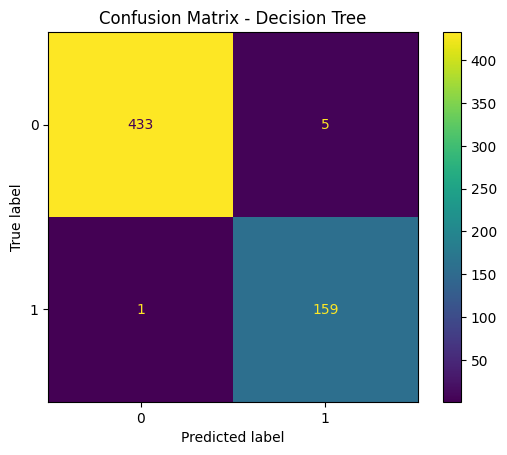

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Melakukan prediksi
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model: {akurasi:.4f} ({akurasi*100:.2f}%)")

# Laporan evaluasi
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Decision Tree")
plt.show()


## **Classification Report**

In [ ]:

from sklearn.metrics import classification_report

print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Kondisi Buruk', 'Kondisi Baik']
))


Classification Report:
               precision    recall  f1-score   support

Kondisi Buruk       1.00      0.99      0.99       438
 Kondisi Baik       0.97      0.99      0.98       160

     accuracy                           0.99       598
    macro avg       0.98      0.99      0.99       598
 weighted avg       0.99      0.99      0.99       598



# **Visualisasikan pohon keputusan**

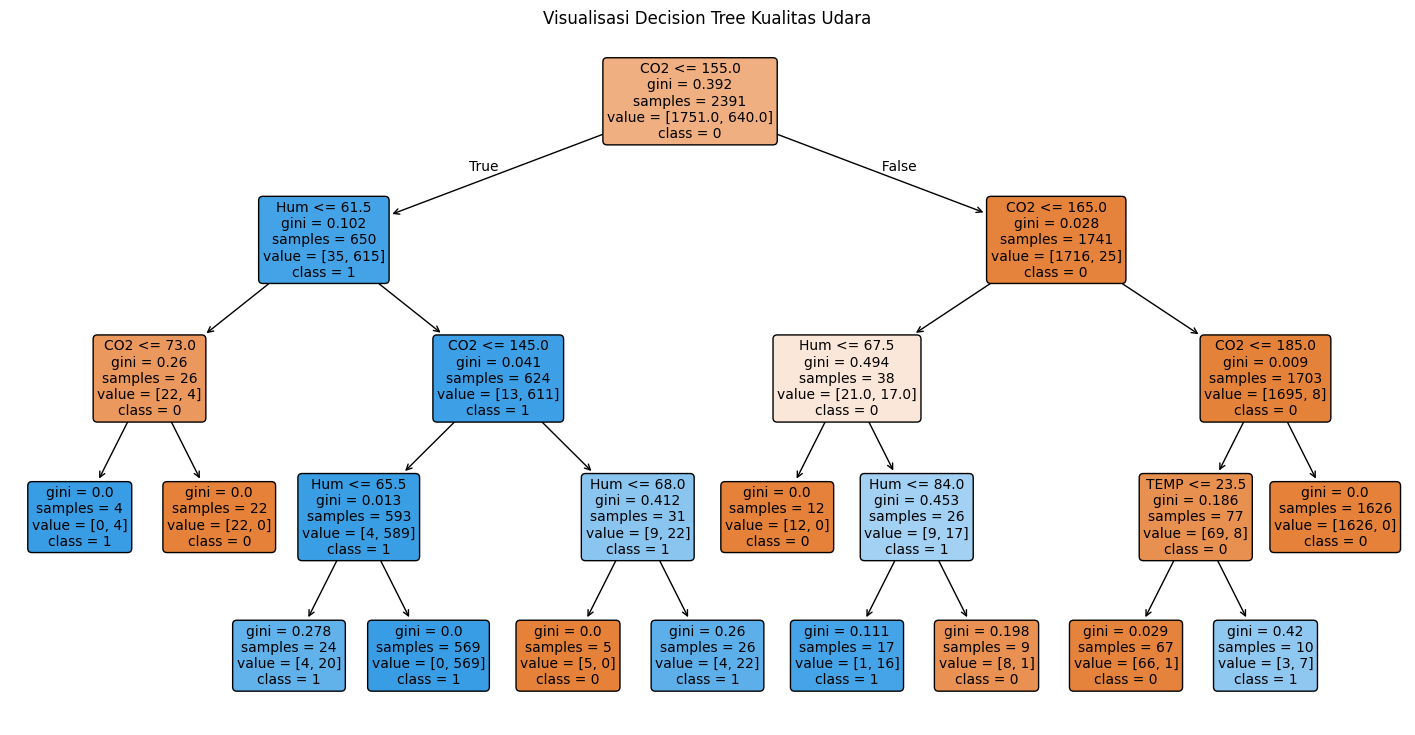

In [ ]:

from sklearn.tree import plot_tree

plt.figure(figsize=(18, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(k) for k in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Visualisasi Decision Tree Kualitas Udara")
plt.show()


# **Uji prediksi satu sampel baru**

In [ ]:

# Contoh nilai uji, bukan hasil pengukuran sensor nyata
sampel_baru = pd.DataFrame(
    [[25.0, 55, 600]],
    columns=['TEMP', 'Hum', 'CO2']
)

prediksi = model.predict(sampel_baru)

print("Prediksi kelas:", prediksi[0])


Prediksi kelas: 0
